# Present Your Solution

## 1. The Client’s Goal
The wildlife control team receives hundreds of squirrel sighting reports from Central Park each day, but staff can only capture and test about 40–50 squirrels. The team needs to decide which reports to investigate first. Our goal is to rank incoming reports so staff can find as many sick squirrels as possible within their daily capture limit.

## 2. What We Learned from the Sightings
Fur color showed the clearest pattern in the training data. About 65% of sightings with black fur and 49% with cinnamon fur were labeled sick, compared with 4% of sightings with gray fur. The disease labels were created for this project, so this pattern would need to be checked against real test results before using fur color to guide field decisions.

Behavior also mattered. About 29% of sightings where the squirrel approached people were labeled sick, compared with 12% of sightings where approaching was not reported. Aggression was harder to identify from the notes. For example, “avoiding a dog” ranked among the ten notes most similar to “aggressive behavior,” even though it describes the squirrel moving away.

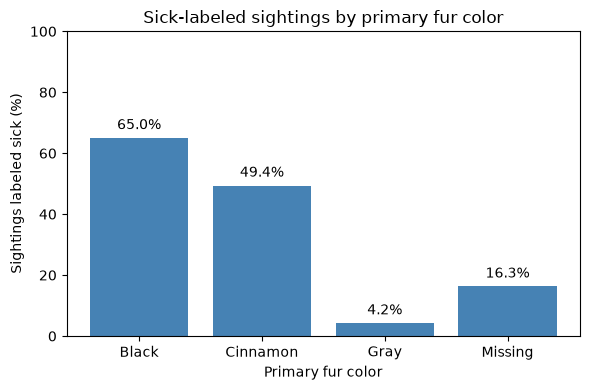

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_parquet("train_set.parquet")
fur_color = train["Primary Fur Color"].fillna("Missing")
sick_rate = train.groupby(fur_color)["diseased"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(sick_rate.index, sick_rate, color="steelblue")
ax.bar_label(bars, fmt="%.1f%%", padding=4)

ax.set_ylim(0, 100)
ax.set_xlabel("Primary fur color")
ax.set_ylabel("Sightings labeled sick (%)")
ax.set_title("Sick-labeled sightings by primary fur color")

plt.tight_layout()
plt.show()

## 3. Why We Selected Random Forest
We selected Random Forest because it performed well across the team’s daily capture range. In validation, it had the highest recall among the four tuned models at both 40 and 50 reports per day. At 45 reports, it identified 71.5% of sick sightings on average, close to Gradient Boosting’s 71.7%. Random Forest also had the highest F1 score at the default threshold (0.595), giving us a second reason to choose it.

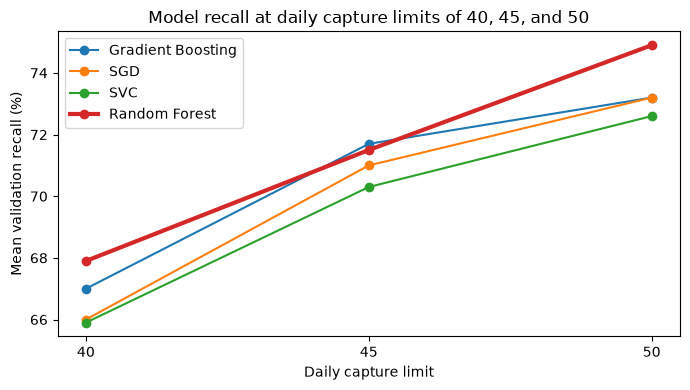

In [2]:
import matplotlib.pyplot as plt

daily_limits = [40, 45, 50]
recall_by_model = {
    "Gradient Boosting": [67.0, 71.7, 73.2],
    "SGD": [66.0, 71.0, 73.2],
    "SVC": [65.9, 70.3, 72.6],
    "Random Forest": [67.9, 71.5, 74.9]
}

fig, ax = plt.subplots(figsize=(7, 4))

for model, recall in recall_by_model.items():
    width = 3 if model == "Random Forest" else 1.5
    ax.plot(daily_limits, recall, marker="o", linewidth=width, label=model)

ax.set_xticks(daily_limits)
ax.set_xlabel("Daily capture limit")
ax.set_ylabel("Mean validation recall (%)")
ax.set_title("Model recall at daily capture limits of 40, 45, and 50")
ax.legend()

plt.tight_layout()
plt.show()

## 4. Results at 40–50 Captures per Day
We scaled each daily limit to the share of that day’s reports in the test set. Across the test period, Random Forest identified 40 of 76 sick sightings at a daily capacity of 40, 44 at a capacity of 45, and 48 at a capacity of 50.

Increasing daily capacity from 45 to 50 added 10 reports to the review list across the test period. Four of those reports were labeled sick, raising recall from 57.9% to 63.2%. Precision changed only slightly, from 44.9% to 44.4%.

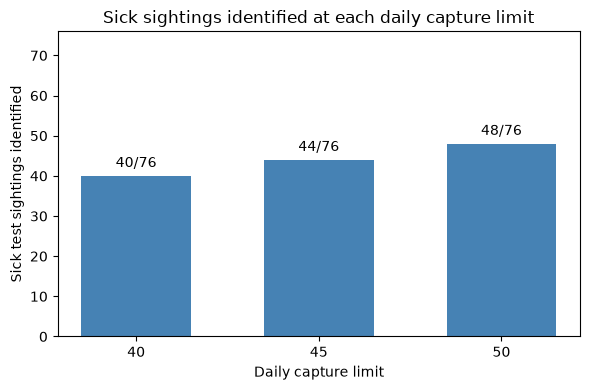

In [1]:
import matplotlib.pyplot as plt

daily_limits = ["40", "45", "50"]
caught = [40, 44, 48]
total_sick = 76

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(daily_limits, caught, color="steelblue", width=0.6)

ax.bar_label(bars, labels=[f"{n}/{total_sick}" for n in caught], padding=4)
ax.set_ylim(0, total_sick)
ax.set_xlabel("Daily capture limit")
ax.set_ylabel("Sick test sightings identified")
ax.set_title("Sick sightings identified at each daily capture limit")

plt.tight_layout()
plt.show()

## 5. Recommendation and Limitations
We recommend using Random Forest to rank incoming reports for staff review. On days when staff can make 50 captures, reviewing more reports may help them find additional sick squirrels. Staff should also read the original notes, especially when a volunteer describes aggression or injury.

The sightings came from a short period in October 2018, and the disease labels were created for this project. Many reports had no behavior notes, and volunteers sometimes described similar actions in different ways. Before relying on the rankings in the field, the team should compare them with actual test results from new sightings and track how many sick squirrels it finds within its daily capture limit.